# CSU lecturer pay by department bucket

Load `csu_uc_salary_schedule_2013-2024-gbw.parquet` and restrict the plots to `source_system == "CSU"` and `role == "lecturer"`, grouped by the existing department buckets.

Pay is annual gross pay in nominal dollars, without inflation or workload/FTE adjustment. Each row is a payroll record, not necessarily a unique person. The distribution pools all available years and CSU campuses; the trend plot separates years. Zero pay is retained; missing pay is excluded and reported below.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import pandas as pd
from IPython.display import display

# Support running from the notebook folder or the repository root.
data_path = Path('csu_uc_salary_schedule_2013-2024-gbw.parquet')
if not data_path.exists():
    data_path = Path("Data-Folding") / data_path

csu = pd.read_parquet(data_path)
lecturers = csu.loc[
    csu["source_system"].eq("CSU") & csu["role"].eq("lecturer"),
                    ["year", "campus", "department", "gross_pay"]].copy()
lecturers["department"] = lecturers["department"].fillna("Unknown")
lecturers["gross_pay"] = pd.to_numeric(lecturers["gross_pay"], errors="coerce")
print(f"CSU lecturer records: {len(lecturers):,}")
print(f"Years: {lecturers['year'].min()}-{lecturers['year'].max()}")
print(f"Missing pay excluded: {lecturers['gross_pay'].isna().sum():,}")
print(f"Zero-pay records retained: {lecturers['gross_pay'].eq(0).sum():,}")
pay = lecturers.dropna(subset=["gross_pay"]).copy()
assert not pay.empty, "No lecturer records with gross pay were found."

summary = (
    pay.groupby("department")["gross_pay"]
    .agg(records="size", median="median", mean="mean",
         p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75))
    .sort_values("median")
)
display(summary.round(2))

CSU lecturer records: 39,571
Years: 2013-2024
Missing pay excluded: 0
Zero-pay records retained: 3,896


,records,median,mean,p25,p75
department,,,,,
Education & Public Administration,4164,18578.0,29130.24,6216.25,46475.25
Engineering,1310,23228.5,35173.72,6997.25,61716.25
Other,2929,23782.0,31541.33,7460.00,50481.00
Medicine & Health Sciences,3514,23796.5,31494.50,8523.75,50286.25
Architecture & Environmental Design,1012,24663.0,28336.80,8347.75,42988.50
"Business, Economics & Finance",3274,32242.5,38785.82,11027.75,61121.75
Humanities & Languages,9122,34154.0,36126.95,12293.25,56317.75
Social Sciences & Communication,6926,35159.5,38464.56,12343.25,58723.25
"Agriculture, Food & Animal",1442,35543.5,36922.00,11231.25,57433.00


In [17]:
csu.columns

Index(['year', 'campus', 'name', 'title_scrapped', 'role', 'title_tc',
       'original_department', 'department', 'gross_pay', 'base_pay',
       'overtime_pay', 'other_pay'],
      dtype='object')

C:\Users\wkmp2\AppData\Local\Temp\ipykernel_61584\194458686.py:45: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = ax.boxplot(


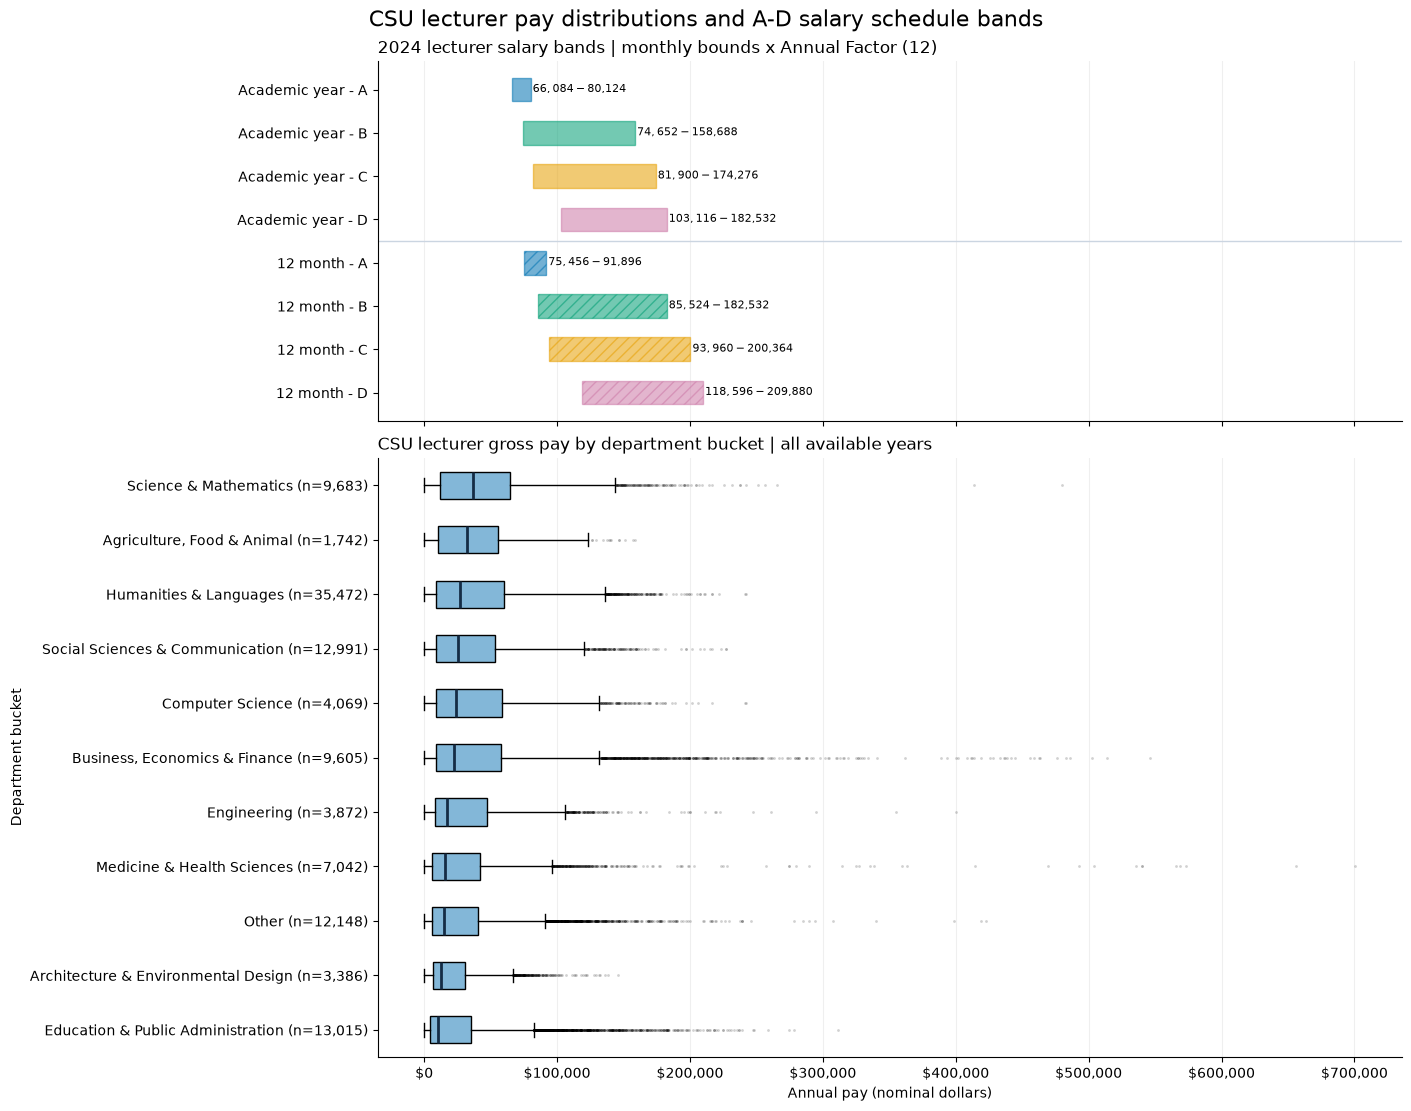

In [61]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Read the exact July 2024 lecturer A-D schedule rows supplied above.
schedule_path = Path('SalaryRecsCSU.csv')
if not schedule_path.exists():
    schedule_path = Path('Data-Folding') / schedule_path
lecturer_bands = pd.read_csv(schedule_path)
lecturer_bands = lecturer_bands.loc[
    lecturer_bands['Class'].isin([2358, 2359])
    & lecturer_bands['Effective Date'].eq('07/01/2024')
    & lecturer_bands['Range Title'].isin(list('ABCD'))
].copy().sort_values(['Class', 'Range Title'])
for column in ['Min Salary', 'Max Salary']:
    lecturer_bands[column] = pd.to_numeric(
        lecturer_bands[column].str.replace(r'[$,]', '', regex=True)
    )
lecturer_bands['annual_low'] = lecturer_bands['Min Salary'] * lecturer_bands['Annual Factor']
lecturer_bands['annual_high'] = lecturer_bands['Max Salary'] * lecturer_bands['Annual Factor']
lecturer_bands['appointment'] = lecturer_bands['Class'].map({2358: 'Academic year', 2359: '12 month'})

order = summary.index.tolist()
fig, (band_ax, ax) = plt.subplots(
    2, 1, figsize=(14, 11), sharex=True,
    gridspec_kw={'height_ratios': [1.2, 2]}, constrained_layout=True,
)
colors = {'A': '#0072B2', 'B': '#009E73', 'C': '#E69F00', 'D': '#CC79A7'}
for pos, (_, row) in enumerate(lecturer_bands.iterrows()):
    band_ax.barh(
        pos, row['annual_high'] - row['annual_low'], left=row['annual_low'],
        height=0.55, color=colors[row['Range Title']], alpha=0.55,
        edgecolor=colors[row['Range Title']],
        hatch='///' if row['Class'] == 2359 else None,
    )
    band_ax.text(row['annual_high'] + 1500, pos,
                 f"${row['annual_low']:,.0f}-${row['annual_high']:,.0f}",
                 va='center', fontsize=8)
band_ax.set_yticks(range(len(lecturer_bands)),
                  lecturer_bands['appointment'] + ' - ' + lecturer_bands['Range Title'])
band_ax.invert_yaxis()
band_ax.set_title('2024 lecturer salary bands | monthly bounds x Annual Factor (12)', loc='left')
band_ax.axhline(3.5, color='#CBD5E1', linewidth=1)

boxes = ax.boxplot(
    [pay.loc[pay['department'].eq(bucket), 'gross_pay'] for bucket in order],
    vert=False, patch_artist=True, showfliers=True,
    flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.18},
    medianprops={'color': '#152c45', 'linewidth': 2},
)
for box in boxes['boxes']:
    box.set_facecolor('#83b7d8')
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels([f"{bucket} (n={summary.loc[bucket, 'records']:,})" for bucket in order])
ax.set_xlabel('Annual pay (nominal dollars)')
ax.set_ylabel('Department bucket')
ax.set_title('CSU lecturer gross pay by department bucket | all available years', loc='left')
for axis in [band_ax, ax]:
    axis.xaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
    axis.grid(axis='x', alpha=0.2)
    axis.set_axisbelow(True)
    axis.spines[['top', 'right']].set_visible(False)
# Leave room for the exact-value labels at the right of the schedule bands.
left, right = ax.get_xlim()
ax.set_xlim(left, max(right, lecturer_bands['annual_high'].max() + 55000))
fig.suptitle('CSU lecturer pay distributions and A-D salary schedule bands', fontsize=16)
plt.show()


Boxes show the middle 50% of records, with a line at the median. Whiskers extend to the most distant values within 1.5 times the interquartile range; dots show values beyond the whiskers. `n` is the number of records with pay.

The upper panel shows the eight July 2024 lecturer A-D salary ranges on the same dollar axis. Monthly bounds are multiplied by the schedule Annual Factor of 12. Academic-year ranges are solid and 12-month ranges are hatched. These are reference salary bands; the boxes show gross pay across all available years, without FTE or inflation adjustment, and do not assign records to lecturer levels.

## Yearly median pay

Separate panels use the same pay scale to make department buckets comparable. Medians reflect the records available in each year, rather than following a fixed set of lecturers.

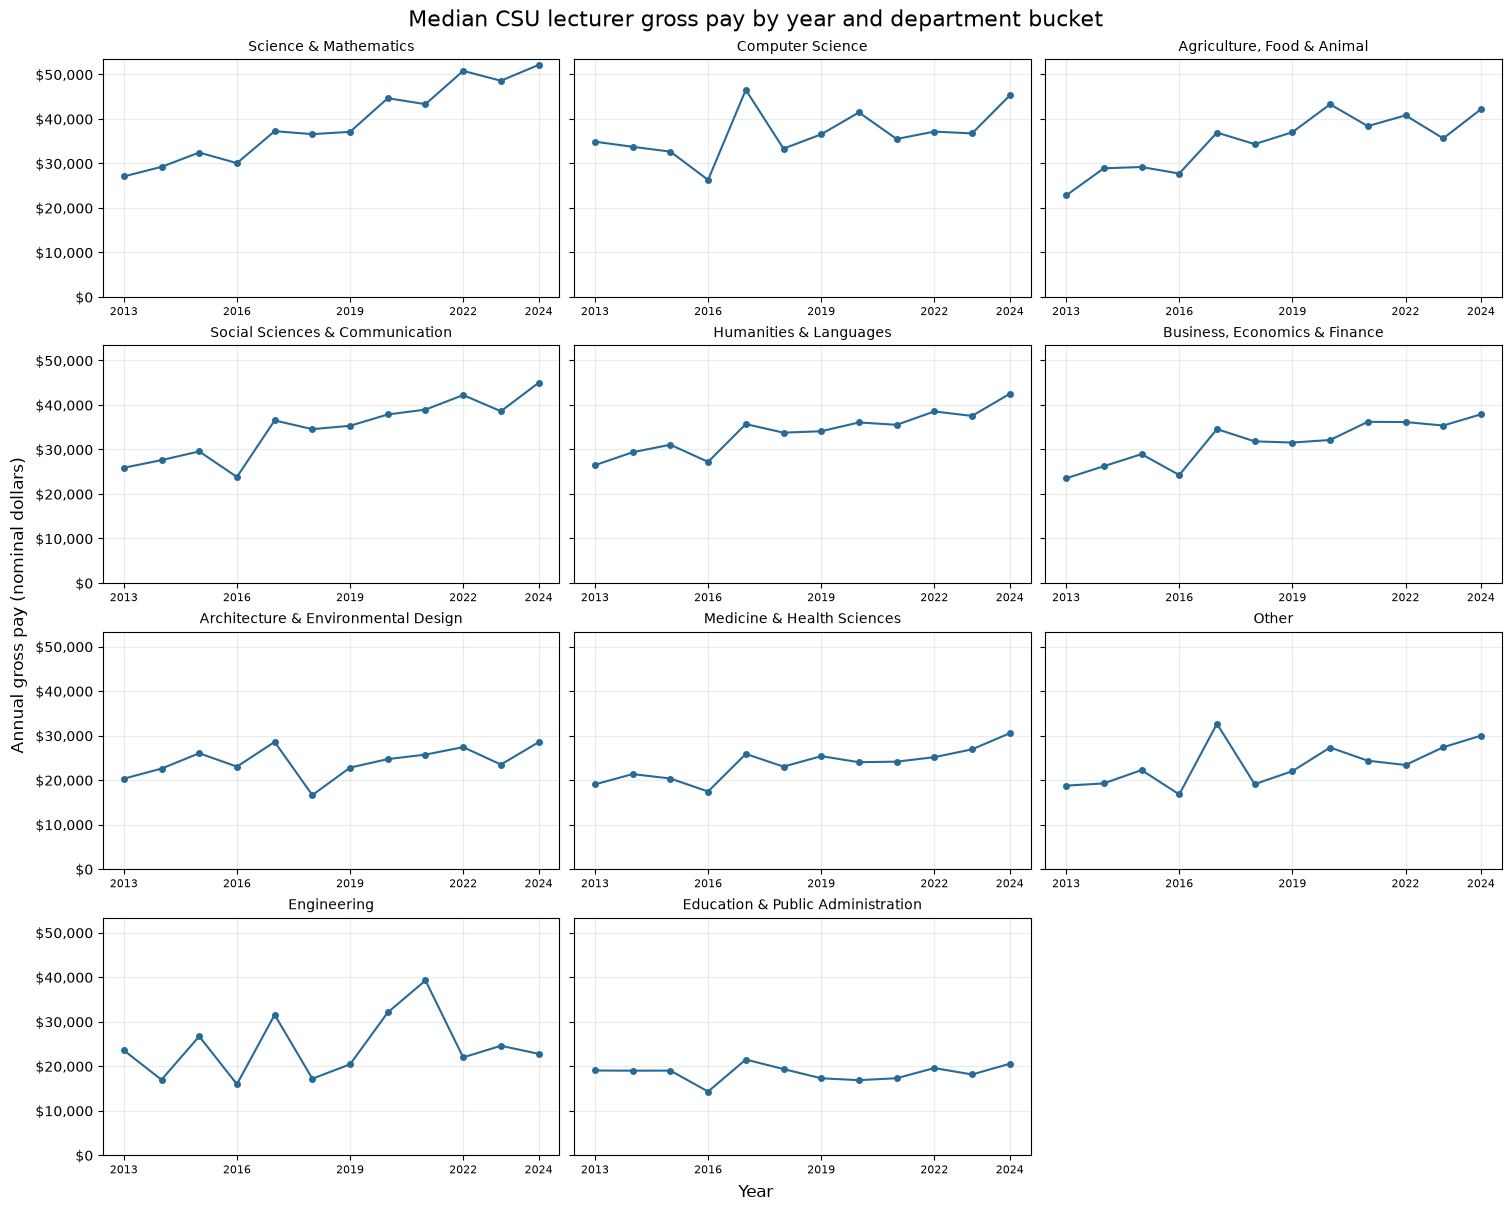

In [ ]:
annual = (
    pay.groupby(["year", "department"])["gross_pay"]
    .agg(median="median", records="size")
    .reset_index()
)
years = sorted(pay["year"].dropna().unique())
fig, axes = plt.subplots(4, 3, figsize=(15, 12), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, bucket in zip(axes.flat, reversed(order)):
    trend = annual.loc[annual["department"].eq(bucket)].set_index("year").reindex(years)
    ax.plot(trend.index, trend["median"], marker="o", markersize=4, color="#286a97")
    ax.set_title(bucket, fontsize=10)
    ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
    ax.set_xticks(years[::3] + ([years[-1]] if years[-1] not in years[::3] else []))
    ax.tick_params(axis="x", labelbottom=True, labelsize=8)
    ax.grid(alpha=0.25)
    ax.set_ylim(bottom=0)
for ax in list(axes.flat)[len(order):]:
    ax.set_visible(False)
fig.suptitle("Median CSU lecturer gross pay by year and department bucket", fontsize=16)
fig.supxlabel("Year")
fig.supylabel("Annual gross pay (nominal dollars)")
plt.show()

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Search all available years, allowing middle names and either name order.
tc_path = Path('transparent_california_no_dup_filtered_csu_salaries_2013-2024 (1).parquet')
if not tc_path.exists():
    tc_path = Path('Data-Folding') / tc_path

tc_df = pd.read_parquet(tc_path)
names = tc_df['name'].astype('string')
francine_arroyo = tc_df.loc[
    names.str.contains(r'\bFrancine\b', case=False, na=False)
    & names.str.contains(r'\bArroyo\b', case=False, na=False)
].sort_values(['year', 'job'])

print(f'Francine Arroyo: {len(francine_arroyo):,} TC records across all available years.')
display(francine_arroyo)


Francine Arroyo: 6 TC records across all available years.


,name,job,department,base,overtime,other,benefitshw,totalpay,totalbenefits,totalpaybenefits,notes,year,agency,status,role
22578,Francine Ann Arroyo,lecturer - academic year,None,5532,0,3114,None,8646,0,8646,employee holds multiple positions.,2013,california state university,None,lecturer
673211,Francine Ann Arroyo,instructional faculty - academic year,None,21664,0,5829,None,27493,13385,40879,None,2022,california state university,None,ladder_faculty
755759,Francine Ann Arroyo,instructional faculty - academic year,None,90761,0,0,None,90761,45669,136430,None,2023,california state university,None,ladder_faculty
755397,Francine Ann Arroyo,ft faculty unit - additional employment,None,0,0,0,None,0,0,0,None,2023,california state university,None,supplemental_teaching_pay
838450,Francine Ann Arroyo,instructional faculty - academic year,None,89352,0,7029,None,96382,48776,145159,None,2024,california state university,None,ladder_faculty
838084,Francine Ann Arroyo,ft faculty unit - additional employment,None,0,0,0,None,0,0,0,None,2024,california state university,None,supplemental_teaching_pay


In [6]:
lecturers = csu.loc[csu["role"].eq("lecturer") & csu["year"].eq(2024),
                    ["year", "campus", "department", "gross_pay"]].copy()

In [28]:
csu.columns

Index(['year', 'campus', 'name', 'title_scrapped', 'role', 'title_tc',
       'original_department', 'department', 'gross_pay', 'base_pay',
       ...
       'Step 29', 'Step 30', 'Step 31', 'Step 32', 'salary_match',
       'salary_schedule_year', 'salary_range_mean', 'salary_low',
       'salary_high', 'salary_expected'],
      dtype='object', length=113)

In [36]:
csu.loc[csu["year"].eq(2024) & csu["source_system"].eq("CSU")] \
    .drop_duplicates(subset="name") \
    .groupby("matched_rank", dropna=False) \
    .size()

matched_rank
assistant professor    1198
associate professor    1671
instructor                1
lecturer class A       4041
professor              3885
NaN                    1045
dtype: int64

In [38]:
csu.loc[csu["year"].eq(2024) &csu["matched_rank"].isna() & csu["source_system"].eq("CSU")].drop_duplicates(subset="name") .groupby("role").size()

role
clinical_adjunct_faculty             4
ladder_faculty                     936
postdoc                              6
researcher_specialist_librarian    163
trainee                              1
dtype: int64

2358,2,07/01/2024,LECTURER - ACADEMIC YEAR,"$5,507.00","$6,677.00",R03,Active,1,2405,"LECTURER A,AY",A,E   ,N,N,J2,F3A,3,3,12,11,M,00,0,Y,,A,09/01/1961,00,F,5507,6677,5959
2358,3,07/01/2024,LECTURER - ACADEMIC YEAR,"$6,221.00","$13,224.00",R03,Active,1,2405,"LECTURER B,AY",B,E   ,N,N,J2,F3A,3,3,12,11,M,00,0,Y,,A,09/01/1961,00,F,6221,13224,7481
2358,4,07/01/2024,LECTURER - ACADEMIC YEAR,"$6,825.00","$14,523.00",R03,Active,1,2405,"LECTURER C,AY",C,E   ,N,N,J2,F3A,3,3,12,11,M,00,0,Y,,A,09/01/1961,00,F,6825,14523,9431
2358,5,07/01/2024,LECTURER - ACADEMIC YEAR,"$8,593.00","$15,211.00",R03,Active,1,2405,"LECTURER D,AY",D,E   ,N,N,J2,F3A,3,3,12,11,M,00,0,Y,,A,09/01/1961,00,F,8593,15211,10347
2359,2,07/01/2024,LECTURER - 12 MONTH,"$6,288.00","$7,658.00",R03,Active,1,2405,"LECTURER A,12",A,E   ,N,N,J2,F3A,3,2,12,11,M,00,0,N,,A,07/01/1962,00,F,6288,7658,6825
2359,3,07/01/2024,LECTURER - 12 MONTH,"$7,127.00","$15,211.00",R03,Active,1,2405,"LECTURER B,12",B,E   ,N,N,J2,F3A,3,2,12,11,M,00,0,N,,A,07/01/1962,00,F,7127,15211,8593
2359,4,07/01/2024,LECTURER - 12 MONTH,"$7,830.00","$16,697.00",R03,Active,1,2405,"LECTURER C,12",C,E   ,N,N,J2,F3A,3,2,12,11,M,00,0,N,,A,07/01/1962,00,F,7830,16697,10849
2359,5,07/01/2024,LECTURER - 12 MONTH,"$9,883.00","$17,490.00",R03,Active,1,2405,"LECTURER D,12",D,E   ,N,N,J2,F3A,3,2,12,11,M,00,0,N,,A,07/01/1962,00,F,9883,17490,11910

In [55]:
csu.columns.tolist()

['year',
 'campus',
 'name',
 'title_scrapped',
 'role',
 'title_tc',
 'original_department',
 'department',
 'gross_pay',
 'base_pay',
 'overtime_pay',
 'other_pay',
 'title',
 'source_system',
 'extracted_rank',
 'rank_source',
 'title_rule',
 'role_adjusted',
 'matched_rank',
 'match_method',
 'unmatched_reason',
 'available_range_titles',
 'Class',
 'Range',
 'Effective Date',
 'Class Title',
 'Min Salary',
 'Max Salary',
 'CBID',
 'Status',
 'Status Code',
 'Pay Letter',
 'Abbreviated Title',
 'Range Title',
 'FLSA',
 'SISA',
 'Shift Differential',
 'Occupational Index',
 'Affirmative Action',
 'Employee Category',
 'Vacation Rate',
 'Annual Factor',
 'Budget Occupation',
 'Salary Per',
 'Campus Code',
 'License Type',
 'AY Class',
 'MPP AGL',
 'Pay Plan',
 'Establish Date',
 'Footnote',
 'Record Type',
 'Minimum Rate',
 'Maximum Rate',
 'SSI Rate',
 'Annual Rate',
 'Semester Rate A',
 'Quarter Rate A',
 'Semester Rate B',
 'Quarter Rate B',
 'Semester Rate C',
 'Quarter Rate C',


In [62]:
lecturers = csu.loc[csu["role"].eq("lecturer") & csu["source_system"].eq("CSU"),
                    ["name","year", "campus", "department", "gross_pay"]].copy()

lecturers.sample(1)

,name,year,campus,department,gross_pay
124117,Shannon Mache,2023,Sonoma State University,Social Sciences & Communication,13020


In [45]:
lecturers.sample(1)

,name,year,campus,department,gross_pay
147366,kamvar farahbod,2024,riverside,"Business, Economics & Finance",19210


In [56]:
csu.loc[csu["name"].eq("kamvar farahbod")][["name", "year", "campus", "department", "gross_pay","title_tc"]]

,name,year,campus,department,gross_pay,title_tc
147366,kamvar farahbod,2024,riverside,"Business, Economics & Finance",19210,None
220636,kamvar farahbod,2022,riverside,Other,40173,None
256036,kamvar farahbod,2021,riverside,"Business, Economics & Finance",11067,None
290104,kamvar farahbod,2020,riverside,"Business, Economics & Finance",16437,None
323953,kamvar farahbod,2019,riverside,"Business, Economics & Finance",18505,None
357708,kamvar farahbod,2018,riverside,"Business, Economics & Finance",30121,None
390300,kamvar farahbod,2017,riverside,"Business, Economics & Finance",21157,None
422308,kamvar farahbod,2016,riverside,"Business, Economics & Finance",13626,None
453612,kamvar farahbod,2015,riverside,"Business, Economics & Finance",6635,None


In [63]:
lecturers.loc[lecturers["name"].eq("Shannon Mache")]

,name,year,campus,department,gross_pay
124109,Shannon Mache,2015,Sonoma State University,Social Sciences & Communication,5752
124110,Shannon Mache,2016,Sonoma State University,Social Sciences & Communication,11913
124111,Shannon Mache,2017,Sonoma State University,Social Sciences & Communication,6377
124112,Shannon Mache,2018,Sonoma State University,Social Sciences & Communication,11272
124113,Shannon Mache,2019,Sonoma State University,Social Sciences & Communication,11676
124114,Shannon Mache,2020,Sonoma State University,Social Sciences & Communication,13532
124115,Shannon Mache,2021,Sonoma State University,Social Sciences & Communication,11841
124116,Shannon Mache,2022,Sonoma State University,Social Sciences & Communication,13497
124117,Shannon Mache,2023,Sonoma State University,Social Sciences & Communication,13020
124118,Shannon Mache,2024,Sonoma State University,Social Sciences & Communication,19053


In [51]:
tc = pd.read_parquet("transparent_california_no_dup_filtered_csu_salaries_2013-2024 (1).parquet")

In [60]:
tc.loc[
    tc["name"].astype("string").str.strip().str.casefold().eq("caroline fairchild")
]

,name,job,department,base,overtime,other,benefitshw,totalpay,totalbenefits,totalpaybenefits,notes,year,agency,status,role
665512,Caroline Fairchild,lecturer - academic year,None,298,0,0,None,298,0,298,None,2022,california state university,None,lecturer
748229,Caroline Fairchild,lecturer - academic year,None,2289,0,99,None,2389,0,2389,None,2023,california state university,None,lecturer
830904,Caroline Fairchild,lecturer - academic year,None,4241,0,10,None,4252,0,4252,None,2024,california state university,None,lecturer


In [64]:
# CSU lecturers whose scraped title does not explicitly say lecturer.
lecturer_records = csu.loc[
    csu["source_system"].eq("CSU") & csu["role"].eq("lecturer")
].copy()

titles = lecturer_records["title_scrapped"].astype("string").str.strip()
titles = titles.replace("", pd.NA)

other_title_lecturers = lecturer_records.loc[
    titles.notna()
    & ~titles.str.contains(r"\b(?:lecturer|lecturtrer|lect)\b", case=False, na=False)
].copy()

print(f"Records with another title: {len(other_title_lecturers):,}")
print(
    "Distinct name/campus pairs:",
    other_title_lecturers[["name", "campus"]].drop_duplicates().shape[0],
)

display(other_title_lecturers["title_scrapped"].value_counts())
display(other_title_lecturers)

Records with another title: 7,438
Distinct name/campus pairs: 1696


title_scrapped
Assistant Professor                                 1614
Professor                                           1541
Associate Professor                                 1108
Temporary Faculty                                    589
Instructional Faculty                                453
                                                    ... 
Associate Professor and Department Chair               1
Associate Professor and Interim Department Chair       1
Head Coach, Volleyball                                 1
Head Coach, Women's Volleyball                         1
Distinguished Professor                                1
Name: count, Length: 139, dtype: int64

,year,campus,name,title_scrapped,role,title_tc,original_department,department,gross_pay,base_pay,...,Step 29,Step 30,Step 31,Step 32,salary_match,salary_schedule_year,salary_range_mean,salary_low,salary_high,salary_expected
27,2014,CSU Bakersfield,Adam Sawyer,Professor,lecturer,lecturer - academic year,Teacher Education,Education & Public Administration,10135,10135,...,NaN,NaN,NaN,NaN,both,2024.0,6582.5,66084.0,91896.0,78990.0
28,2015,CSU Bakersfield,Adam Sawyer,Professor,lecturer,lecturer - academic year,Teacher Education,Education & Public Administration,27625,25051,...,NaN,NaN,NaN,NaN,both,2024.0,6582.5,66084.0,91896.0,78990.0
29,2016,CSU Bakersfield,Adam Sawyer,Professor,lecturer,lecturer - academic year,Teacher Education,Education & Public Administration,5616,4212,...,NaN,NaN,NaN,NaN,both,2024.0,6582.5,66084.0,91896.0,78990.0
42,2014,CSU Bakersfield,Alberto Cruz,Professor,lecturer,lecturer - academic year,Computer Sciences,Computer Science,15919,15938,...,NaN,NaN,NaN,NaN,both,2024.0,6582.5,66084.0,91896.0,78990.0
246,2019,CSU Bakersfield,Anna Cruz,Professor,lecturer,lecturer - academic year,Geology,Science & Mathematics,12039,11777,...,NaN,NaN,NaN,NaN,both,2024.0,6582.5,66084.0,91896.0,78990.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124129,2015,Sonoma State University,Silvio Machado,Instructional Faculty,lecturer,lecturer - academic year,Department of Counseling,Social Sciences & Communication,13840,6920,...,NaN,NaN,NaN,NaN,both,2024.0,6582.5,66084.0,91896.0,78990.0
124130,2016,Sonoma State University,Silvio Machado,Instructional Faculty,lecturer,lecturer - academic year,Department of Counseling,Social Sciences & Communication,30510,24799,...,NaN,NaN,NaN,NaN,both,2024.0,6582.5,66084.0,91896.0,78990.0
124359,2014,Sonoma State University,Thomas Targett,Instructional Faculty,lecturer,lecturer - academic year,Dept Chem Biochem Phys Astr,Science & Mathematics,70894,49807,...,NaN,NaN,NaN,NaN,both,2024.0,6582.5,66084.0,91896.0,78990.0
124382,2014,Sonoma State University,Wendy Ostroff,Dept Chair AY,lecturer,lecturer - academic year,Hutchins School of Lib Studies,Humanities & Languages,32507,32407,...,NaN,NaN,NaN,NaN,both,2024.0,6582.5,66084.0,91896.0,78990.0


In [65]:
lecturers = csu.loc[
    csu["source_system"].eq("CSU")
    & csu["matched_rank"].astype("string").str.contains(
        r"\blecturer\b", case=False, na=False
    ),
    ["year", "campus", "department", "gross_pay"],
].copy()

lecturers["department"] = lecturers["department"].fillna("Unknown")
lecturers["gross_pay"] = pd.to_numeric(lecturers["gross_pay"], errors="coerce")
pay = lecturers.dropna(subset=["gross_pay"]).copy()

summary = (
    pay.groupby("department")["gross_pay"]
    .agg(
        records="size",
        median="median",
        mean="mean",
        p25=lambda s: s.quantile(0.25),
        p75=lambda s: s.quantile(0.75),
    )
    .sort_values("median")
)

print(f"CSU matched-lecturer records: {len(pay):,}")
display(summary.round(2))

CSU matched-lecturer records: 40,761


,records,median,mean,p25,p75
department,,,,,
Education & Public Administration,4266,19093.0,29984.53,6403.00,47743.00
Engineering,1337,23626.0,36013.47,6982.00,63094.00
Medicine & Health Sciences,3613,24534.0,32395.86,8780.00,51956.00
Other,3035,24682.0,32795.00,7751.00,52338.00
Architecture & Environmental Design,1066,25650.0,31227.29,9235.00,45698.00
"Business, Economics & Finance",3376,33204.5,40065.93,11142.50,62931.25
Humanities & Languages,9320,34923.0,37170.30,12480.00,57298.00
Social Sciences & Communication,7153,35947.0,39787.78,12687.00,60246.00
"Agriculture, Food & Animal",1534,37537.5,38999.42,12055.50,59804.25


In [74]:
golden_csu = pd.read_parquet("golden_csu_2013-2024.parquet")
golden_csu.loc[golden_csu["name"].eq("Phuong Nguyen")  & golden_csu["year"].eq(2024)]

,year,campus,name,title,role,original_department,department,gross_pay,base_pay,overtime_pay,other_pay
107835,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,ladder_faculty,Humanities & Communication,Humanities & Languages,0,0,0,0
107836,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,ladder_faculty,Humanities & Communication,Humanities & Languages,157440,111220,0,46219
107837,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,lecturer,Humanities & Communication,Humanities & Languages,0,0,0,0
107838,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,lecturer,Humanities & Communication,Humanities & Languages,10010,9885,0,125
107839,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,lecturer,Humanities & Communication,Humanities & Languages,27949,20699,0,7250
107840,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,lecturer,Humanities & Communication,Humanities & Languages,124528,124528,0,0
107841,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,supplemental_teaching_pay,Humanities & Communication,Humanities & Languages,0,0,0,0
107842,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,supplemental_teaching_pay,Humanities & Communication,Humanities & Languages,1050,0,0,1050


In [75]:
golden_csu = pd.read_parquet("golden_csu_2013-2024-gbw.parquet")
golden_csu.loc[golden_csu["name"].eq("Phuong Nguyen")  & golden_csu["year"].eq(2024)]

,year,campus,name,title_scrapped,role,title_tc,original_department,department,gross_pay,base_pay,overtime_pay,other_pay
121570,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,ladder_faculty,instructional faculty - academic year,Humanities & Communication,Humanities & Languages,0,0,0,0
121571,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,ladder_faculty,department chair - academic year,Humanities & Communication,Humanities & Languages,157440,111220,0,46219
121572,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,lecturer,lecturer - academic year,Humanities & Communication,Humanities & Languages,0,0,0,0
121573,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,lecturer,lecturer - 12 month,Humanities & Communication,Humanities & Languages,27949,20699,0,7250
121574,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,supplemental_teaching_pay,"instructional faculty, summer session - state ...",Humanities & Communication,Humanities & Languages,0,0,0,0
121575,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,supplemental_teaching_pay,"instructional faculty, extension non-credit",Humanities & Communication,Humanities & Languages,1050,0,0,1050


In [68]:
csu.loc[csu["name"].eq("Phuong Nguyen") & csu["source_system"].eq("CSU") & csu["year"].eq(2024)]

,year,campus,name,title_scrapped,role,title_tc,original_department,department,gross_pay,base_pay,...,Step 29,Step 30,Step 31,Step 32,salary_match,salary_schedule_year,salary_range_mean,salary_low,salary_high,salary_expected
87681,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,ladder_faculty,instructional faculty - academic year,Humanities & Communication,Humanities & Languages,0,0,...,NaN,NaN,NaN,NaN,both,2024.0,11761.0,81900.0,200364.0,141132.0
87682,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,ladder_faculty,department chair - academic year,Humanities & Communication,Humanities & Languages,157440,111220,...,NaN,NaN,NaN,NaN,both,2024.0,11761.0,81900.0,200364.0,141132.0
87683,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,lecturer,lecturer - academic year,Humanities & Communication,Humanities & Languages,0,0,...,NaN,NaN,NaN,NaN,both,2024.0,6582.5,66084.0,91896.0,78990.0
87684,2024,"California State University, Monterey Bay",Phuong Nguyen,Associate Professor,lecturer,lecturer - 12 month,Humanities & Communication,Humanities & Languages,27949,20699,...,NaN,NaN,NaN,NaN,both,2024.0,6582.5,66084.0,91896.0,78990.0


Golden -> Dropping Middle -> Supplemental

### Deduplicated lecturer counts versus the CSU reference

Compare 2024 CSU records whose matched rank contains lecturer with the reference `lecturer_total`. Count each name once per campus, retaining all 22 reference campuses. This uses the requested matched-rank definition; lecturer assignment can still reflect the default matching rules discussed above. No pay threshold or departure exclusions are applied.

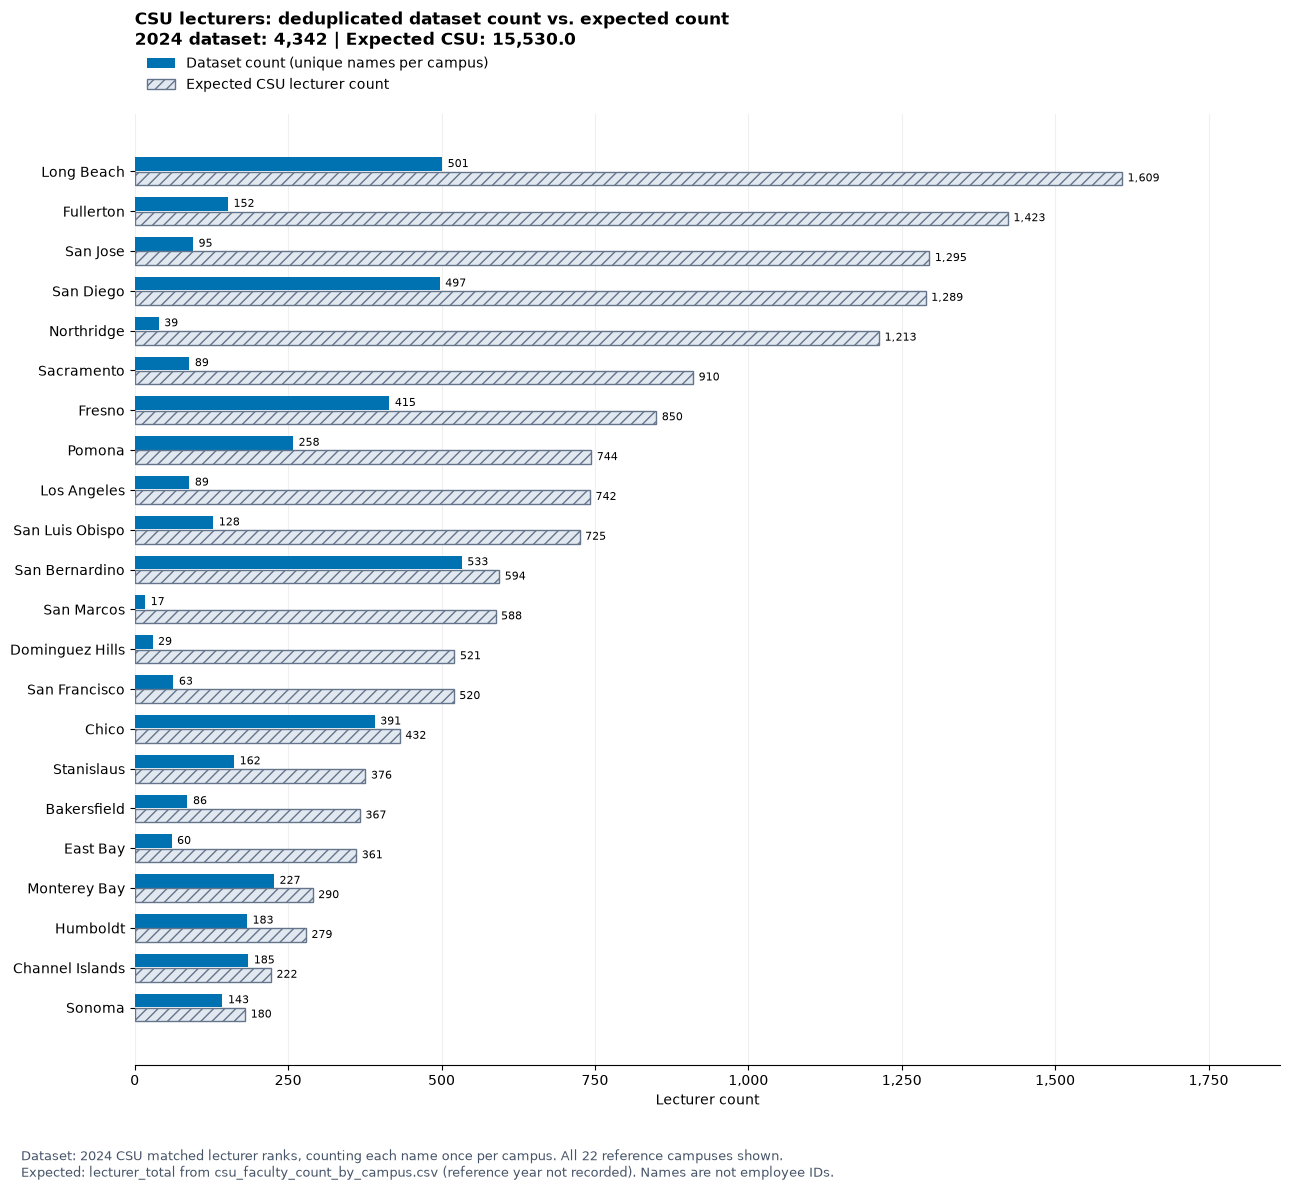

,expected_CSU_count,dataset_count,gap
campus,,,
Long Beach,1609.0,501,-1108.0
Fullerton,1423.0,152,-1271.0
San Jose,1295.0,95,-1200.0
San Diego,1289.0,497,-792.0
Northridge,1213.0,39,-1174.0
Sacramento,910.0,89,-821.0
Fresno,850.0,415,-435.0
Pomona,744.0,258,-486.0
Los Angeles,742.0,89,-653.0


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

reference_path = Path('csu_faculty_count_by_campus.csv')
if not reference_path.exists():
    reference_path = Path('Data-Folding') / reference_path
expected_lecturers = pd.read_csv(reference_path)[['campus', 'lecturer_total']]
# The CSV also contains an Overall summary row, not an individual campus.
expected_lecturers = expected_lecturers.loc[
    ~expected_lecturers['campus'].astype('string').str.strip().str.casefold().isin(['overall', 'total'])
].copy()
expected_lecturers['lecturer_total'] = pd.to_numeric(expected_lecturers['lecturer_total'], errors='raise')
if expected_lecturers['lecturer_total'].isna().any():
    raise ValueError('Expected lecturer counts are missing for a campus.')

# Use the latest requested lecturer definition: matched rank, CSU, 2024.
lecturer_count_rows = csu.loc[
    csu['source_system'].eq('CSU') & csu['year'].eq(2024)
    & csu['matched_rank'].astype('string').str.contains(r'\blecturer\b', case=False, na=False),
    ['campus', 'name'],
].copy()
campus_labels = {'CSU Bakersfield': 'Bakersfield',
 'CSU Channel Islands': 'Channel Islands',
 'California State University, Chico': 'Chico',
 'California State University, Dominguez Hills': 'Dominguez Hills',
 'California State University, East Bay': 'East Bay',
 'California State University, Fresno': 'Fresno',
 'California State University, Fullerton': 'Fullerton',
 'Cal Poly Humboldt': 'Humboldt',
 'CSU Long Beach': 'Long Beach',
 'CSU Los Angeles': 'Los Angeles',
 'California State University, Monterey Bay': 'Monterey Bay',
 'CSU Northridge': 'Northridge',
 'Cal Poly Pomona': 'Pomona',
 'California State University, Sacramento': 'Sacramento',
 'CSU San Bernardino': 'San Bernardino',
 'San Diego State University': 'San Diego',
 'San Francisco State University': 'San Francisco',
 'San Jose State University': 'San Jose',
 'Cal Poly San Luis Obispo': 'San Luis Obispo',
 'California State University San Marcos': 'San Marcos',
 'Sonoma State University': 'Sonoma',
 'California State University, Stanislaus': 'Stanislaus'}
lecturer_count_rows['count_campus'] = lecturer_count_rows['campus'].map(campus_labels)
if lecturer_count_rows['count_campus'].isna().any():
    raise ValueError('Some lecturer campuses need a reference-name mapping.')

# Deduplicate within campus, so repeated payroll lines or departments count once.
observed_lecturers = (
    lecturer_count_rows.groupby('count_campus')['name'].nunique().rename('dataset_count')
)
lecturer_count_comparison = (
    expected_lecturers.set_index('campus').rename(columns={'lecturer_total': 'expected_CSU_count'})
    .join(observed_lecturers, validate='one_to_one')
)
lecturer_count_comparison['dataset_count'] = (
    lecturer_count_comparison['dataset_count'].fillna(0).astype(int)
)
lecturer_count_comparison['gap'] = (
    lecturer_count_comparison['dataset_count'] - lecturer_count_comparison['expected_CSU_count']
)
lecturer_count_comparison = lecturer_count_comparison.sort_values('expected_CSU_count', ascending=False)

y = np.arange(len(lecturer_count_comparison))
fig, ax = plt.subplots(figsize=(13, 12))
dataset_bars = ax.barh(y - 0.18, lecturer_count_comparison['dataset_count'],
                       height=0.34, color='#0072B2', label='Dataset count (unique names per campus)')
expected_bars = ax.barh(y + 0.18, lecturer_count_comparison['expected_CSU_count'],
                        height=0.34, color='#E2E8F0', edgecolor='#64748B', hatch='///',
                        label='Expected CSU lecturer count')
for bars in [dataset_bars, expected_bars]:
    ax.bar_label(bars, labels=[f'{bar.get_width():,.0f}' for bar in bars], padding=4, fontsize=8)
ax.set_yticks(y, lecturer_count_comparison.index)
ax.invert_yaxis()
ax.set_xlim(0, max(1, lecturer_count_comparison[['dataset_count', 'expected_CSU_count']].max().max()) * 1.16)
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.set_xlabel('Lecturer count')
ax.set_title(
    'CSU lecturers: deduplicated dataset count vs. expected count\n'
    f"2024 dataset: {lecturer_count_comparison['dataset_count'].sum():,} | "
    f"Expected CSU: {lecturer_count_comparison['expected_CSU_count'].sum():,}",
    loc='left', fontweight='bold', pad=50,
)
ax.legend(frameon=False, loc='lower left', bbox_to_anchor=(0, 1.01))
ax.set_axisbelow(True)
ax.grid(axis='x', alpha=0.2)
ax.spines[['top', 'right', 'left']].set_visible(False)
fig.text(0.02, 0.015,
         'Dataset: 2024 CSU matched lecturer ranks, counting each name once per campus. All 22 reference campuses shown.\n'
         'Expected: lecturer_total from csu_faculty_count_by_campus.csv (reference year not recorded). Names are not employee IDs.',
         fontsize=9, color='#475569')
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()
display(lecturer_count_comparison)
